<p style="text-align: right; margin: 0; line-height: 0;"><img width="100px" height="auto" src="../../.admin/img/eth_logo.png"></p>

<h1 style="text-align: center;">00 Introduction</h1>
<hr>

## **1. Check Course Environment**

<div class="alert alert-light">

  **Name:** Stefan Sykes
  
  **Matriculation Number:** 11-250-693
  
</div>

### 1.1 Introduction

The hands-on exercises in this course use Jupyter notebooks to explore and test the concepts discussed in the lectures. A notebook combines explanatory text with executable code: you read a section, run the code beneath it, change something, and observe the effect.

This first notebook confirms that your computer is ready for the exercises that follow. It assumes that you have already completed the installation guide [`README.md`](../../README.md), found in the top-level folder of the course material. If you have not yet done so, please complete it before continuing.

To run a cell, select it and press **Shift + Enter**, or select the small triangle to the left of the cell. Please run the cells in the order in which they appear.

### 1.2 Install the Course Libraries

The notebooks rely on a number of Python libraries. The next cell installs them into the Python interpreter that is currently running this notebook. The installation takes few minute and is required only once.

> If you work in a virtual environment, select it as the notebook kernel before running the cell, so that the libraries are installed in the intended place.

In [1]:
# Check which kernel you're actually using
import sys
print(sys.executable)
print(sys.version)

c:\Users\stefa\Documents\0000_ETH\276-0003-00L Mobile Computing HS2026\gitlab\MobileComputing\.venv\Scripts\python.exe
3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]


In [2]:
%pip install -r "../../.admin/notebooks/requirements.txt"
print("Installation complete. Continue with the next cell.")

  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached pyserial-3.5-py2.py3-none-any.whl.metadata (1.6 kB)
  Using cached nbformat-5.11.1-py3-none-any.whl.metadata (3.7 kB)
  Using cached serial-0.0.97-py2.py3-none-any.whl.metadata (889 bytes)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached pyentrp-2.2.0-py3-none-any.whl.metadata (3.6 kB)
  Using cached sounddevice-0.5.6-py3-none-win_amd64.whl.metadata (1.4 kB)
  Using cached paramiko-5.0.0-py3-none-any.whl.metadata (3.7 kB)
  Using cached scikit_image-0.26.0-cp313-cp313-win_amd64.whl.metadata (15 kB)
  Using cached datasets-5.0.1-py3-none-any.whl.metadata (23 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached widgetsnbextension-4.0.16-py3-none-any.whl.metadata (1.6 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
  Using cached fastjsonschema-2.22.2-py3-none-any.whl.metadata (2.1 kB)
  Using cached jsonschema-4


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
import shutil
import sys

print("Python:", sys.executable)
print("JAVA_HOME:", os.environ.get("JAVA_HOME"))
print("java:", shutil.which("java"))
print("javac:", shutil.which("javac"))

Python: c:\Users\stefa\Documents\0000_ETH\276-0003-00L Mobile Computing HS2026\gitlab\MobileComputing\.venv\Scripts\python.exe
JAVA_HOME: C:\Program Files\Java\jdk-27
java: C:\Program Files\Common Files\Oracle\Java\javapath\java.EXE
javac: C:\Program Files\Common Files\Oracle\Java\javapath\javac.EXE


In [2]:
import subprocess

print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr)
print(subprocess.run(["javac", "-version"], capture_output=True, text=True).stderr)

java version "27" 2026-09-15
Java(TM) SE Runtime Environment (build 27+35-2325)
Java HotSpot(TM) 64-Bit Server VM (build 27+35-2325, mixed mode, sharing)




### 1.3 Check Your Environment

The next cell examines each component required by the course and reports what it finds. It installs nothing and changes nothing; it only reports.

In [3]:
import importlib.metadata as metadata
import platform
import shutil
import subprocess


def command_version(command, arguments):
    """Return the first line reported by an external command, or None if the command is absent."""
    executable = shutil.which(command)
    if executable is None:
        return None
    result = subprocess.run([executable, *arguments], capture_output=True, text=True)
    lines = (result.stdout + result.stderr).strip().splitlines()
    return lines[0] if lines else "present"


def package_version(distribution):
    """Return the installed version of a Python package, or None if it is absent."""
    try:
        return metadata.version(distribution)
    except metadata.PackageNotFoundError:
        return None


checks = [
    ("Python", platform.python_version()),
    ("Git", command_version("git", ["--version"])),
    ("Java runtime", command_version("java", ["-version"])),
    ("Java compiler", command_version("javac", ["-version"])),
]

for library in ["numpy", "pandas", "matplotlib", "scipy", "ipywidgets",
                "pillow", "scikit-image", "pyserial", "paramiko"]:
    checks.append((library, package_version(library)))

print(f"{'Component':<16}{'Found':<40}Status")
print("-" * 62)
missing = 0
for component, found in checks:
    if found is None:
        missing += 1
    print(f"{component:<16}{found or '-':<40}{'OK' if found else 'MISSING'}")
print("-" * 62)

if missing == 0:
    print("All components are available.")
else:
    print(f"{missing} component(s) missing. Try to restart the notebook and make sure you are using the correct Python environment.")

Component       Found                                   Status
--------------------------------------------------------------
Python          3.13.7                                  OK
Git             git version 2.54.0.windows.1            OK
Java runtime    java version "27" 2026-09-15            OK
Java compiler   javac 27                                OK
numpy           2.5.3                                   OK
pandas          3.0.6                                   OK
matplotlib      3.11.2                                  OK
scipy           1.18.1                                  OK
ipywidgets      8.1.9                                   OK
pillow          12.3.0                                  OK
scikit-image    0.26.0                                  OK
pyserial        3.5                                     OK
paramiko        5.0.0                                   OK
--------------------------------------------------------------
All components are available.


### 1.4 Compile and Run a Java Program

Several of the wireless-network laboratories compile and execute Java programs. The next cell performs the same operation in miniature: it writes a small Java file, compiles it with `javac`, runs the compiled program, and then removes the temporary files.

In [4]:
from pathlib import Path
import subprocess

java_file = Path("HelloMobileComputing.java")
java_file.write_text('public class HelloMobileComputing { public static void main(String[] args) { System.out.println("Hello Java"); } }')

try:
    subprocess.run(["javac", str(java_file)], check=True)
    subprocess.run(["java", "HelloMobileComputing"], check=True)
except subprocess.CalledProcessError as e:
    print(f"Java compilation or execution was not successful: {e}")
finally:
    java_file.unlink(missing_ok=True)
    Path("HelloMobileComputing.class").unlink(missing_ok=True)

### 1.5 Your First Plot

Most notebooks in this course present their results as figures. The next cell draws a simple curve.

After running it, change the values in `y` and run the cell again. The figure is redrawn immediately. This cycle of editing a cell and running it again is how you will work with every notebook in the course.

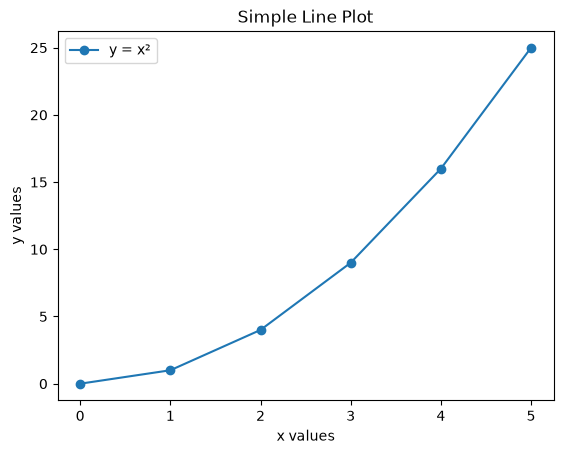

In [5]:
import matplotlib.pyplot as plt

x = [0, 1, 2, 3, 4, 5]
y = [0, 1, 4, 9, 16, 25]

plt.plot(x, y, label='y = x²', marker='o')
plt.title('Simple Line Plot')
plt.xlabel('x values')
plt.ylabel('y values')
plt.legend()
plt.show()

---
### 1.7 Hands-On Exercise

<p><b>This hands-on exercise is not graded.</b></p>
<div class="alert alert-block alert-info">All questions are optional. Fill in any responses you wish to provide, save this notebook as an <code>.ipynb</code> file, and upload it to the <a href="https://moodle-app2.let.ethz.ch/mod/assign/view.php?id=1446570">ungraded test assignment on Moodle</a>. See the <a href="../../03_Assignments/Submission-Guidelines.md">submission guidelines</a> for how to submit your work.</div>


**OPTIONAL: Are our submission guidelines including how to use A.I. clear to you? What question do you have, if any?**

All clear.

**OPTIONAL: Which A.I. tool will you use when working on the assignments? Any commercially available assistant is permitted, for example ChatGPT, Google Gemini, Microsoft Copilot or SwissGPT.**

Claude CLI.

**OPTIONAL: How many notebooks are there in the `01_Data_and_Signals` folder?**

8

**OPTIONAL: What is a Git Repository? What is the difference between Git, GitLab, and GitHub? What does the command `git clone` do?**

Git repository: project folder whose files and changes are tracked using Git incl. the project's history, allowing changes to be recorded, compared, and reverted.
Git: version control system. GitLab and GitHub are platforms that host Git repositories and provide additional features such as collaboration, issue tracking, merge requests/pull requests, and CI/CD.
The command git clone creates a local copy of a remote Git repository, including its files and Git history, so that the repository can be worked on locally.

**OPTIONAL: Did you read through and understand all the tasks in this Notebook? Are there any shortcomings, missing parts, or sections that should be improved?**

All clear.